# Bassac River Water Level Forecasting (2020–2026)
## 07. Hydrological Data Visualizations & Correlation Analysis

This notebook provides visual analysis of the cleaned datasets for the **Bassac River Water Level Forecasting** project (ITM-390, Group 8).

### Analytical Goals:
1. **Station Handover & Continuous Water Level:** Inspect the unified 2020–2026 daily series spliced from `Bassac_01` (Koh Thum, 2020–2024) and calibrated `Koh_Khel` (2024–2026).
2. **Seasonal Cycles & Multi-Year Regimes:** Characterize dry season, rising limb, monsoon crest, and falling recession across different hydrological years.
3. **Upstream Mekong Discharge Impact:** Analyze downstream water level response to upstream flows at Phnom Penh (Copernicus GloFAS), including cross-correlation lags and hydraulic hysteresis.
4. **Subnational Precipitation (Kandal KH08):** Study satellite-derived dekadal rainfall (CHIRPS) patterns and examine correlations with daily river height changes.
5. **Predictor Correlations & Dynamics:** Compute cross-correlations across all 11 model inputs and the next-day target ($WL_{\text{next}}$) to guide time-series regression.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

# Set clean visualization defaults
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.titlesize"] = 13
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["legend.fontsize"] = 10
plt.rcParams["figure.dpi"] = 120

# Resolve project paths (works whether run from repo root or inside src/)
def get_project_root() -> Path:
    cwd = Path.cwd()
    if (cwd / "data" / "processed").exists():
        return cwd
    if (cwd.parent / "data" / "processed").exists():
        return cwd.parent
    if (cwd / "Machine-Learning---Fall2026" / "data" / "processed").exists():
        return cwd / "Machine-Learning---Fall2026"
    return cwd

ROOT_DIR = get_project_root()
PROCESSED_DIR = ROOT_DIR / "data" / "processed"

print(f"Project root resolved to: {ROOT_DIR}")
print(f"Processed data directory: {PROCESSED_DIR}")

Project root resolved to: c:\Users\USER\Desktop\AI&ML\school\2-ML\0-labs\4-final\Machine-Learning---Fall2026
Processed data directory: c:\Users\USER\Desktop\AI&ML\school\2-ML\0-labs\4-final\Machine-Learning---Fall2026\data\processed


## 1. Load Processed Datasets
We load the four cleaned CSV datasets generated by scripts `01` through `04`:
- `bassac_daily.csv`: Daily mean water level at Koh Thum (Jun 2020 – May 2024)
- `kohkhel_daily.csv`: DHRW Koh Khel daily water level (Jun 2020 – Nov 2026)
- `glofas_daily.csv`: Simulated upstream daily river discharge at Phnom Penh ($m^3/s$)
- `rain_kandal_dekad.csv`: 10-day subnational rainfall indicators for Kandal Province

In [2]:
df_bassac = pd.read_csv(PROCESSED_DIR / "bassac_daily.csv")
df_kohkhel = pd.read_csv(PROCESSED_DIR / "kohkhel_daily.csv")
df_glofas = pd.read_csv(PROCESSED_DIR / "glofas_daily.csv")
df_rain = pd.read_csv(PROCESSED_DIR / "rain_kandal_dekad.csv")

# Convert all date columns to pandas datetime
df_bassac["date"] = pd.to_datetime(df_bassac["date"])
df_kohkhel["date"] = pd.to_datetime(df_kohkhel["date"])
df_glofas["date"] = pd.to_datetime(df_glofas["date"])
df_rain["date"] = pd.to_datetime(df_rain["date"])

print(f"Bassac_01 (Koh Thum) : {len(df_bassac):>5} days ({df_bassac['date'].min().date()} to {df_bassac['date'].max().date()})")
print(f"Koh Khel (DHRW)      : {len(df_kohkhel):>5} days ({df_kohkhel['date'].min().date()} to {df_kohkhel['date'].max().date()})")
print(f"GloFAS Discharge     : {len(df_glofas):>5} days ({df_glofas['date'].min().date()} to {df_glofas['date'].max().date()})")
print(f"Kandal Rainfall      : {len(df_rain):>5} dekads ({df_rain['date'].min().date()} to {df_rain['date'].max().date()})")

Bassac_01 (Koh Thum) :  1438 days (2020-06-19 to 2024-05-26)
Koh Khel (DHRW)      :  1498 days (2020-06-17 to 2026-11-11)
GloFAS Discharge     :  3235 days (2018-01-01 to 2026-11-09)
Kandal Rainfall      :  1647 dekads (1981-01-01 to 2026-09-21)


## 2. Station Handover & Spliced 2020–2026 Hydrograph

`Bassac_01_ori.csv` ends on **2024-05-26**. Continuous records are extended through **2026-11-11** using `Koh_Khel` (starting 2024-07-01).

Because Koh Khel is ~15 km upstream on a different gauge zero datum, we apply the linear calibration derived from the 643 shared days (`2020–2023`, $r = 0.9957$):
$$\text{WL}_{\text{calibrated}} = 0.7936 \times \text{WL}_{\text{raw}} - 0.4725$$

This brings the station datum discrepancy down from an average of $1.60\text{ m}$ to an MAE of $0.093\text{ m}$ ($9.3\text{ cm}$).

In [3]:
# 1. Apply calibration equation
a_cal, b_cal = 0.7936, -0.4725
df_kohkhel["WL_cal"] = a_cal * df_kohkhel["WL_raw"] + b_cal

# 2. Build continuous timeline
p1 = df_bassac[["date", "WL"]].copy()
p1["station_source"] = "Bassac_01 (Koh Thum)"

p2 = df_kohkhel[df_kohkhel["date"] >= "2024-07-01"][["date", "WL_cal"]].copy()
p2 = p2.rename(columns={"WL_cal": "WL"})
p2["station_source"] = "Koh Khel (Calibrated)"

full_timeline = pd.date_range("2020-06-19", "2026-11-11", freq="D", name="date")
df_unified = pd.DataFrame({"date": full_timeline})
df_unified = df_unified.merge(p1, on="date", how="left")
df_unified = df_unified.merge(p2, on="date", how="left", suffixes=["_b", "_k"])

df_unified["WL"] = df_unified["WL_b"].combine_first(df_unified["WL_k"])
df_unified["station_source"] = df_unified["station_source_b"].combine_first(df_unified["station_source_k"])
df_unified = df_unified.drop(columns=["WL_b", "station_source_b", "WL_k", "station_source_k"])

print(f"Unified sequence: {len(df_unified)} calendar days")
print(f"Valid water level days: {df_unified['WL'].notna().sum()}")
print(f"Missing days: {df_unified['WL'].isna().sum()} (includes the 35-day June 2024 station gap)")

Unified sequence: 2337 calendar days
Valid water level days: 2178
Missing days: 159 (includes the 35-day June 2024 station gap)


### Plot 1: Complete 2020–2026 Hydrograph
Displays the multi-year progression of water levels, identifying station transition, flood peaks, and annual low flows.

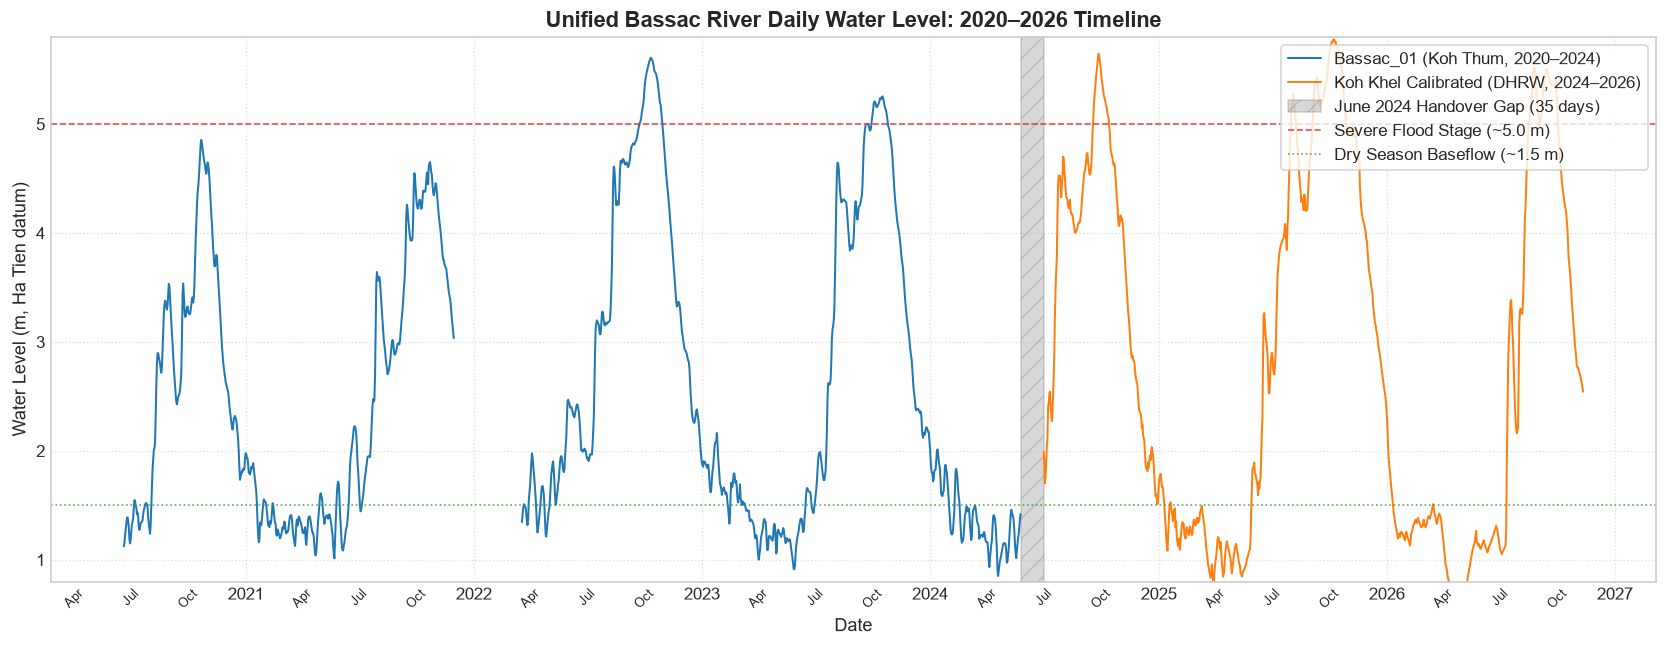

In [4]:
fig, ax = plt.subplots(figsize=(14, 5.5))

# Plot primary segment: Bassac_01
mask_b = df_unified["station_source"] == "Bassac_01 (Koh Thum)"
ax.plot(df_unified.loc[mask_b, "date"], df_unified.loc[mask_b, "WL"],
        color="#1f77b4", linewidth=1.2, label="Bassac_01 (Koh Thum, 2020–2024)")

# Plot extended segment: Koh Khel calibrated
mask_k = df_unified["station_source"] == "Koh Khel (Calibrated)"
ax.plot(df_unified.loc[mask_k, "date"], df_unified.loc[mask_k, "WL"],
        color="#ff7f0e", linewidth=1.2, label="Koh Khel Calibrated (DHRW, 2024–2026)")

# Shade the June 2024 handover gap
ax.axvspan(pd.Timestamp("2024-05-26"), pd.Timestamp("2024-07-01"),
           color="gray", alpha=0.3, hatch="//", label="June 2024 Handover Gap (35 days)")

# Reference flood & low-flow water levels
ax.axhline(5.0, color="#d62728", linestyle="--", linewidth=1.0, alpha=0.8, label="Severe Flood Stage (~5.0 m)")
ax.axhline(1.5, color="#2ca02c", linestyle=":", linewidth=1.0, alpha=0.8, label="Dry Season Baseflow (~1.5 m)")

ax.set_title("Unified Bassac River Daily Water Level: 2020–2026 Timeline", fontsize=13, fontweight="bold")
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Water Level (m, Ha Tien datum)", fontsize=11)
ax.set_ylim(0.8, 5.8)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_formatter(mdates.DateFormatter("%b"))
ax.tick_params(axis="x", which="minor", labelsize=8, rotation=45)

ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

This graph shows daily water levels on the Bassac River from 2020 to early 2027, combining two station records (blue for Koh Thum through mid-2024, orange for the calibrated Koh Khel series afterward) with a short gap in June 2024. Levels fluctuate seasonally, regularly rising above the severe-flood threshold (~5 m) during peak wet seasons and falling toward the dry-season baseflow (~1.5 m) in the intervening months, illustrating the river’s typical annual flood-pulse cycle and the continuity of the record across the station handover.

Most importantly, in every October, the water level raised more than 4 meters, which is a severe flood stage. While that's true, April is where the water level is really low, just below 1.5 meters. This is a remarkable finding.

## 3. Hydrological Seasonality & Multi-Year Regimes

The lower Bassac River follows an annual hydrological cycle determined by the monsoon:
- **Dry Season (Dec–May):** Low flow (~1.3–1.8 m), strongly modulated by semi-diurnal tides (~0.7 m/day).
- **Rising Limb (Jun–Aug):** Monsoon rains in the upper basin initiate sharp water level surges.
- **Flood Peak (Sep–Oct):** Annual flood peak crests, typically reaching 4.5–5.3 m.
- **Falling Limb / Recession (Nov–Dec):** Draining southward toward the South China Sea.

### Plot 2: Day-of-Year (DOY) Hydrograph Overlay
Compares the seasonal cycle across individual calendar years (2020 through 2026) to highlight variations in flood peak timing and volume (e.g., strong flood of 2022 vs. milder crests).

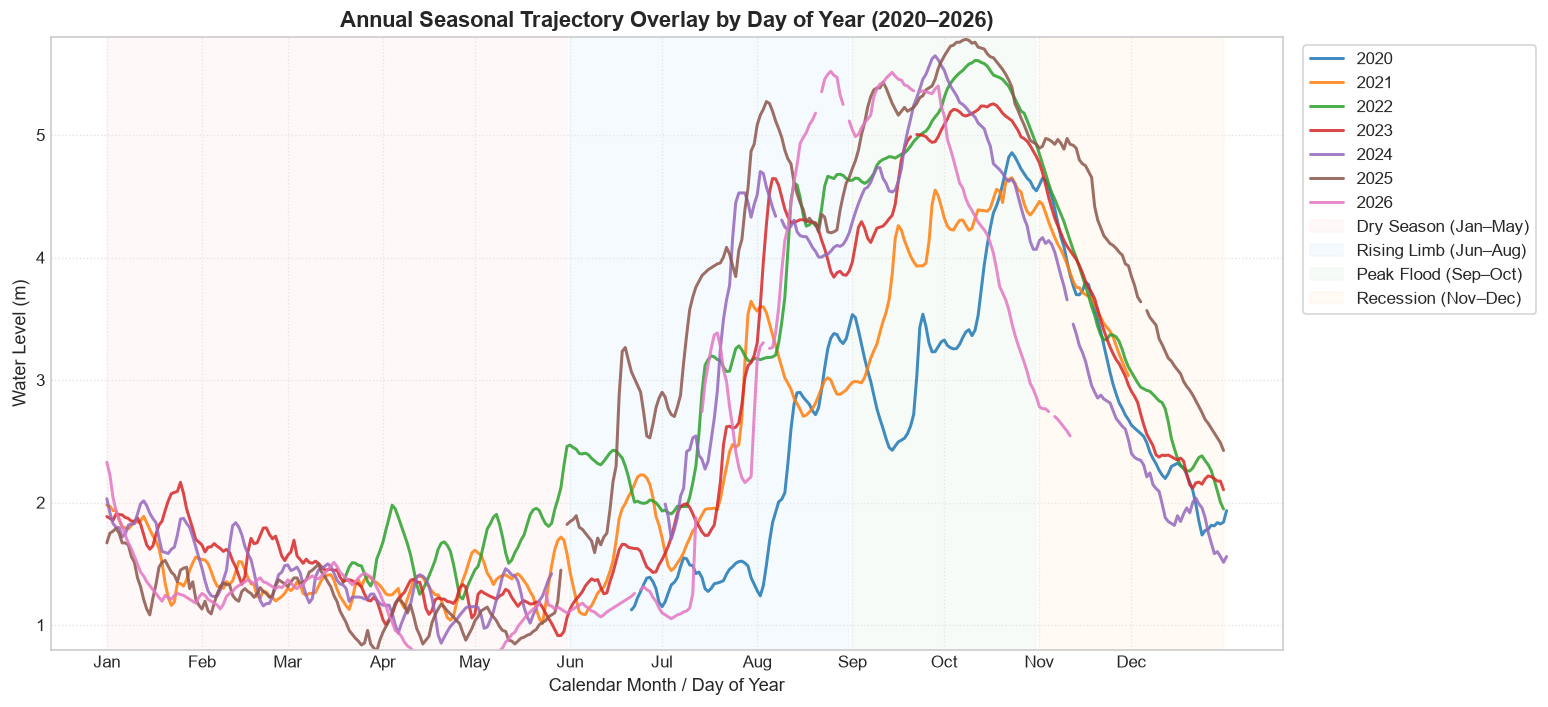

In [5]:
df_unified["year"] = df_unified["date"].dt.year
df_unified["doy"] = df_unified["date"].dt.dayofyear

fig, ax = plt.subplots(figsize=(13, 6))
years = sorted(df_unified["year"].unique())
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]

for yr, color in zip(years, palette):
    subset = df_unified[df_unified["year"] == yr].sort_values("doy")
    if len(subset.dropna(subset=["WL"])) > 30:
        ax.plot(subset["doy"], subset["WL"], label=f"{yr}", color=color, linewidth=1.8, alpha=0.85)

# Month dividers on DOY axis
month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.set_xticks(month_starts)
ax.set_xticklabels(month_names)

# Shaded hydrological season bands
ax.axvspan(1, 151, color="#ffebee", alpha=0.35, label="Dry Season (Jan–May)")
ax.axvspan(152, 243, color="#e3f2fd", alpha=0.35, label="Rising Limb (Jun–Aug)")
ax.axvspan(244, 304, color="#e8f5e9", alpha=0.35, label="Peak Flood (Sep–Oct)")
ax.axvspan(305, 365, color="#fff3e0", alpha=0.35, label="Recession (Nov–Dec)")

ax.set_title("Annual Seasonal Trajectory Overlay by Day of Year (2020–2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Calendar Month / Day of Year", fontsize=11)
ax.set_ylabel("Water Level (m)", fontsize=11)
ax.set_ylim(0.8, 5.8)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True)
plt.tight_layout()
plt.show()

This chart overlays each year’s daily water-level trajectory (2020–2026) on a common day-of-year axis, revealing a consistent seasonal cycle: low and relatively stable levels through the dry season (Jan–May), a sharp rise from June to August, peak flooding in September–October (often exceeding 5 m), and a steady recession from November onward. Year-to-year differences appear mainly in peak height and timing—some years (e.g., 2022, 2025) reach higher or more prolonged floods—while the overall shape of the annual hydrograph remains similar.

This further proves that October has the highest chance of flooding, while from Jan to May shows steady water level across 6 years' data.

### Plot 3: Monthly Water Level Distributions (Boxplots)
Examines median levels, interquartile ranges, and extreme values across all 12 calendar months.

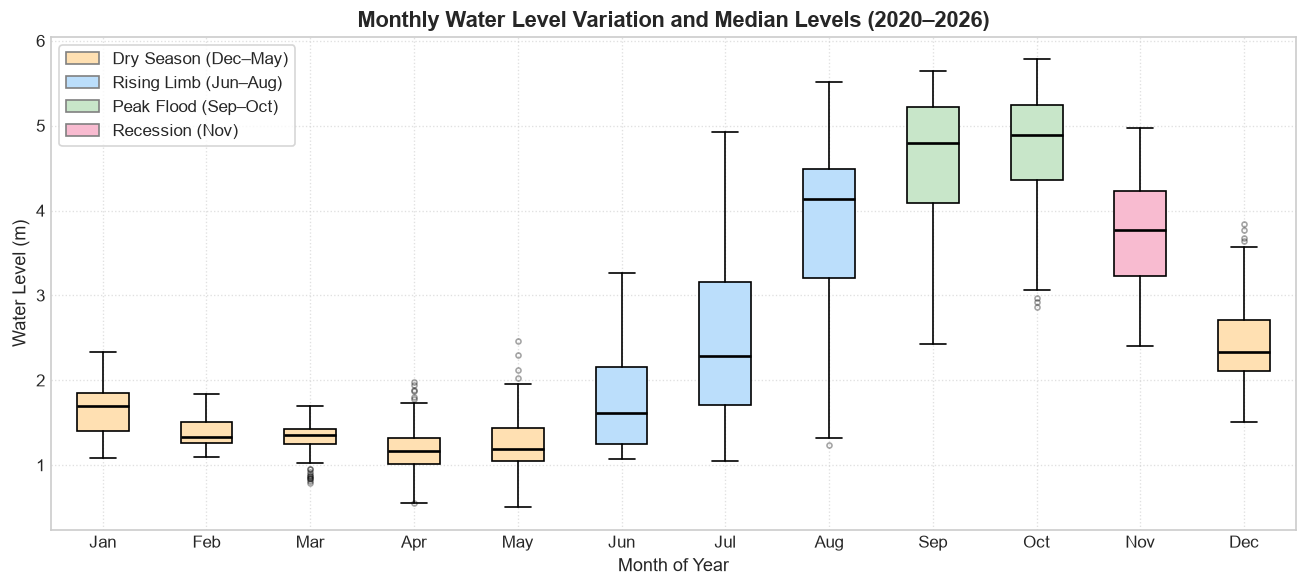

In [6]:
df_unified["month"] = df_unified["date"].dt.month
monthly_groups = [df_unified[df_unified["month"] == m]["WL"].dropna().values for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(monthly_groups, patch_artist=True,
                tick_labels=month_names,
                medianprops=dict(color="black", linewidth=1.6),
                flierprops=dict(marker="o", markersize=3, alpha=0.35))

# Color boxplots by hydrological season
season_colors = {
    "dry": "#ffe0b2",      # Dec - May
    "rising": "#bbdefb",   # Jun - Aug
    "peak": "#c8e6c9",     # Sep - Oct
    "recession": "#f8bbd0" # Nov
}

for i, box in enumerate(bp["boxes"]):
    m = i + 1
    if m in [12, 1, 2, 3, 4, 5]:
        box.set_facecolor(season_colors["dry"])
    elif m in [6, 7, 8]:
        box.set_facecolor(season_colors["rising"])
    elif m in [9, 10]:
        box.set_facecolor(season_colors["peak"])
    else:
        box.set_facecolor(season_colors["recession"])

ax.set_title("Monthly Water Level Variation and Median Levels (2020–2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Month of Year", fontsize=11)
ax.set_ylabel("Water Level (m)", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.6)

legend_handles = [
    Patch(facecolor=season_colors["dry"], edgecolor="gray", label="Dry Season (Dec–May)"),
    Patch(facecolor=season_colors["rising"], edgecolor="gray", label="Rising Limb (Jun–Aug)"),
    Patch(facecolor=season_colors["peak"], edgecolor="gray", label="Peak Flood (Sep–Oct)"),
    Patch(facecolor=season_colors["recession"], edgecolor="gray", label="Recession (Nov)")
]
ax.legend(handles=legend_handles, loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

This is another prove. It is becoming a pattern.

This box-plot chart summarizes the distribution of daily water levels for each calendar month across 2020–2026, with boxes showing the median and interquartile range and whiskers/outliers indicating extremes. Levels stay low and relatively stable through the dry season (Dec–May), begin rising in June–July, reach their highest medians and greatest variability during the peak-flood months of September–October (often near or above 5 m), then decline through the November recession and into December. The clear seasonal progression and month-to-month spread highlight both the typical annual flood pulse and the year-to-year variability within each phase.

## 4. Upstream Mekong River Discharge (Phnom Penh Confluence)

The Mekong confluence at Phnom Penh (Chaktomuk) controls downstream discharge into the Bassac River branch.
- GloFAS discharge $Q$ ($m^3/s$) is modeled ~55 km upstream of Koh Khel.
- Water travel time from Phnom Penh to Kandal stations is approximately 1 to 2 days.

### Plot 4: Dual-Axis Time Series (Discharge vs. Water Level)
Illustrates how upstream discharge swells and drains relative to downstream water height.

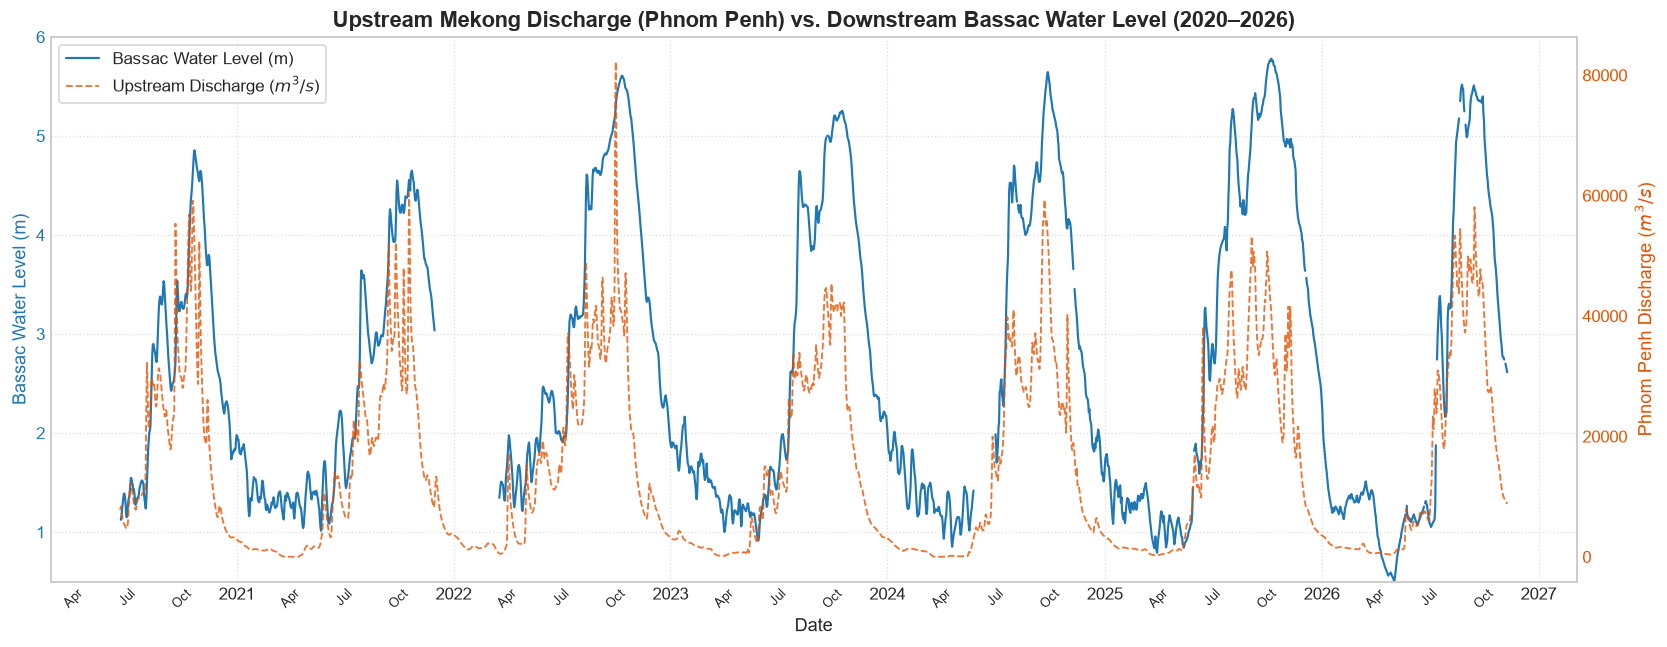

In [7]:
df_hydro = pd.merge(df_unified[["date", "WL"]], df_glofas[["date", "upstream_discharge"]], on="date", how="inner")

fig, ax1 = plt.subplots(figsize=(14, 5.5))

# Left axis: Bassac Water Level
c_wl = "#1f77b4"
ax1.set_xlabel("Date", fontsize=11)
ax1.set_ylabel("Bassac Water Level (m)", color=c_wl, fontsize=11)
line1 = ax1.plot(df_hydro["date"], df_hydro["WL"], color=c_wl, linewidth=1.3, label="Bassac Water Level (m)")
ax1.tick_params(axis="y", labelcolor=c_wl)
ax1.set_ylim(0.5, 6.0)

# Right axis: Upstream Discharge
ax2 = ax1.twinx()
c_q = "#e65100"
ax2.set_ylabel("Phnom Penh Discharge ($m^3/s$)", color=c_q, fontsize=11)
line2 = ax2.plot(df_hydro["date"], df_hydro["upstream_discharge"], color=c_q, linewidth=1.1, alpha=0.8, linestyle="--", label="Upstream Discharge ($m^3/s$)")
ax2.tick_params(axis="y", labelcolor=c_q)
ax2.grid(False)

# Combine legend labels
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)

ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.xaxis.set_minor_formatter(mdates.DateFormatter("%b"))
ax1.tick_params(axis="x", which="minor", labelsize=8, rotation=45)

ax1.set_title("Upstream Mekong Discharge (Phnom Penh) vs. Downstream Bassac Water Level (2020–2026)", fontsize=13, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()



The orange line (Mekong discharge at Phnom Penh) and the blue line (Bassac water level) rise and fall at almost the same times each year.

When a lot of water starts flowing past Phnom Penh, the Bassac water level usually goes up a few days to about 1–2 weeks later. That short delay is the “lag” — the time it takes for the extra water to travel downstream and raise the river level on the Bassac.

In most years the peaks line up very closely, showing that the Mekong is the main driver of the Bassac’s floods, with only a small travel-time delay.

### Plot 5: Cross-Correlation Lag Analysis & Hydraulic Hysteresis
- **Cross-Correlation:** Tests lag values $k \in [-5, +10]$ days between discharge and water level to identify downstream wave propagation time.
- **Hydraulic Hysteresis:** The relationship between discharge and water level forms a looping rating curve caused by channel backwater and floodplain storage.

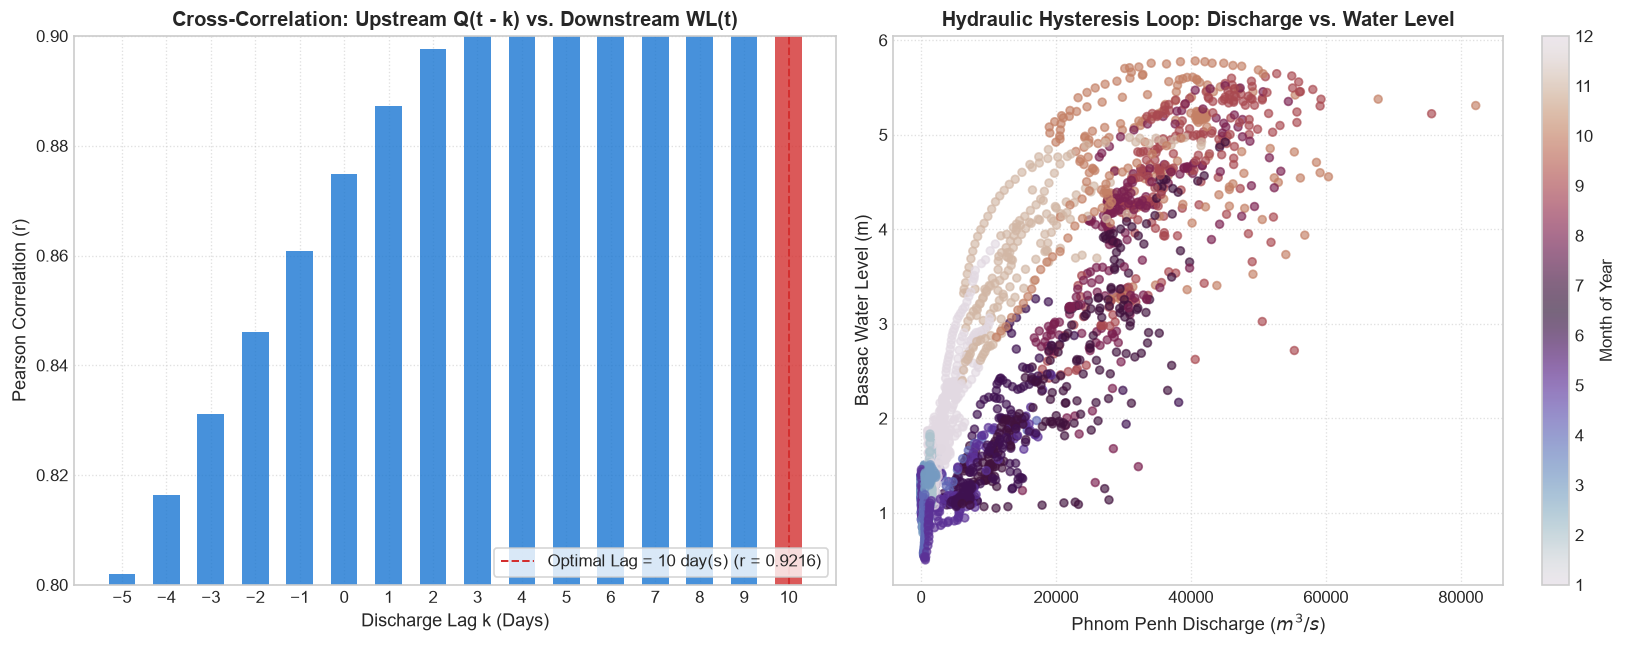

In [8]:
# 1. Calculate Cross-Correlation for lags from -5 to +10 days
lags = list(range(-5, 11))
ccf_vals = []
clean_h = df_hydro.dropna(subset=["WL", "upstream_discharge"]).sort_values("date")

for k in lags:
    if k >= 0:
        r = clean_h["WL"].corr(clean_h["upstream_discharge"].shift(k))
    else:
        r = clean_h["WL"].shift(-k).corr(clean_h["upstream_discharge"])
    ccf_vals.append(r)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: CCF
bar_colors = ["#1976d2" if val < max(ccf_vals) else "#d32f2f" for val in ccf_vals]
ax1.bar(lags, ccf_vals, color=bar_colors, width=0.6, alpha=0.8)
peak_lag = lags[int(np.argmax(ccf_vals))]
max_corr = max(ccf_vals)

ax1.axvline(peak_lag, color="#d32f2f", linestyle="--", linewidth=1.2,
            label=f"Optimal Lag = {peak_lag} day(s) (r = {max_corr:.4f})")
ax1.set_title("Cross-Correlation: Upstream Q(t - k) vs. Downstream WL(t)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Discharge Lag k (Days)", fontsize=11)
ax1.set_ylabel("Pearson Correlation (r)", fontsize=11)
ax1.set_xticks(lags)
ax1.set_ylim(0.80, 0.90)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", frameon=True)

# Subplot 2: Hysteresis Loop
clean_h["month"] = clean_h["date"].dt.month
sc = ax2.scatter(clean_h["upstream_discharge"], clean_h["WL"],
                 c=clean_h["month"], cmap="twilight", alpha=0.65, s=22)
cbar = plt.colorbar(sc, ax=ax2, ticks=range(1, 13))
cbar.set_label("Month of Year", fontsize=10)

ax2.set_title("Hydraulic Hysteresis Loop: Discharge vs. Water Level", fontsize=12, fontweight="bold")
ax2.set_xlabel("Phnom Penh Discharge ($m^3/s$)", fontsize=11)
ax2.set_ylabel("Bassac Water Level (m)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()



**Left chart:** This shows how well the Mekong discharge at Phnom Penh matches the Bassac water level when we shift the discharge forward or backward in time. The correlation gets strongest when we shift the discharge by **10 days**. That means the Bassac water level responds best to what the Mekong was doing about 10 days earlier — this is the average travel-time lag between the two places.

**Right chart:** This plots discharge against water level and colors the points by month. The points form a loop (not a single line). That “loop” shape is called hysteresis: the water level is often higher on the way up (rising flood) than on the way down (falling flood) for the same amount of discharge. This is normal in large rivers because of the time it takes for water to fill and then empty the channel and floodplains.

## 5. Subnational Precipitation Influence (Kandal Province KH08)

Kandal rainfall is recorded every 10 days (dekad) via CHIRPS.
- `rfh`: 10-day cumulative rainfall (mm)
- `r1h`: 1-month cumulative rainfall (soil saturation proxy)
- `r3h`: 3-month cumulative rainfall (monsoon strength indicator)
- `rfq`: Rainfall anomaly percentage of normal

### Plot 6: Hyetograph & Hydrograph Comparison
Compares local 10-day rainfall bars (inverted) with downstream water level fluctuations over the 2020–2026 timeline.

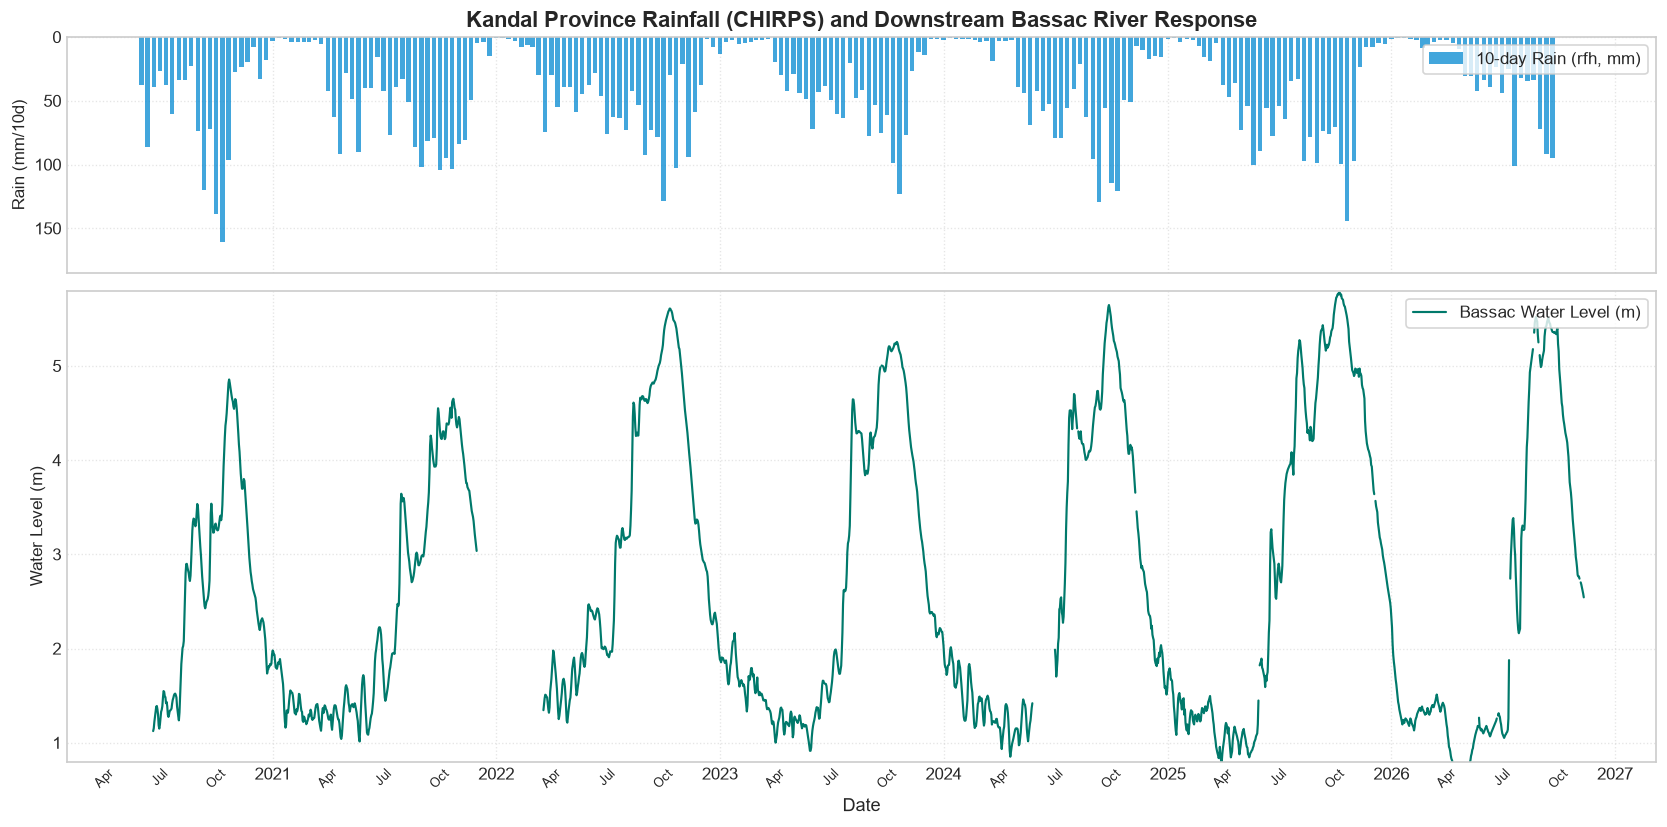

In [9]:
df_rain_recent = df_rain[df_rain["date"] >= "2020-06-01"].sort_values("date")

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                                     gridspec_kw={"height_ratios": [1, 2]})

# Top plot: Inverted rainfall hyetograph
ax_top.bar(df_rain_recent["date"], df_rain_recent["rfh"], width=7, color="#0288d1", alpha=0.75, label="10-day Rain (rfh, mm)")
ax_top.set_ylabel("Rain (mm/10d)", fontsize=10)
ax_top.set_ylim(max(df_rain_recent["rfh"].dropna()) * 1.15, 0)  # Inverted axis convention
ax_top.set_title("Kandal Province Rainfall (CHIRPS) and Downstream Bassac River Response", fontsize=13, fontweight="bold")
ax_top.grid(True, linestyle=":", alpha=0.5)
ax_top.legend(loc="upper right", frameon=True)

# Bottom plot: Water Level Hydrograph
ax_bot.plot(df_unified["date"], df_unified["WL"], color="#00796b", linewidth=1.3, label="Bassac Water Level (m)")
ax_bot.set_ylabel("Water Level (m)", fontsize=10)
ax_bot.set_xlabel("Date", fontsize=11)
ax_bot.set_ylim(0.8, 5.8)
ax_bot.grid(True, linestyle=":", alpha=0.5)
ax_bot.legend(loc="upper right", frameon=True)

ax_bot.xaxis.set_major_locator(mdates.YearLocator())
ax_bot.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
ax_bot.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax_bot.xaxis.set_minor_formatter(mdates.DateFormatter("%b"))
ax_bot.tick_params(axis="x", which="minor", labelsize=8, rotation=45)

plt.tight_layout()
plt.show()

The top panel shows rainfall in Kandal Province (near the Bassac) as blue bars — the longer the bar, the more rain fell in that 10-day period.

The bottom panel shows the Bassac River water level (green line).You can see that heavy local rain (long blue bars) often happens during the same months when the river is rising or already high. However, the biggest jumps in water level still follow the main Mekong flood pulse more than local rain alone. Local rainfall can add extra water and make peaks a bit higher or last longer, but it is not the main driver of the big seasonal floods.

### Plot 7: Local Rain Rate vs. River Daily Change ($\Delta \text{WL}$)
Evaluates whether intense local rain events drive sharp short-term river rise rates ($\Delta \text{WL} = \text{WL}_t - \text{WL}_{t-1}$).

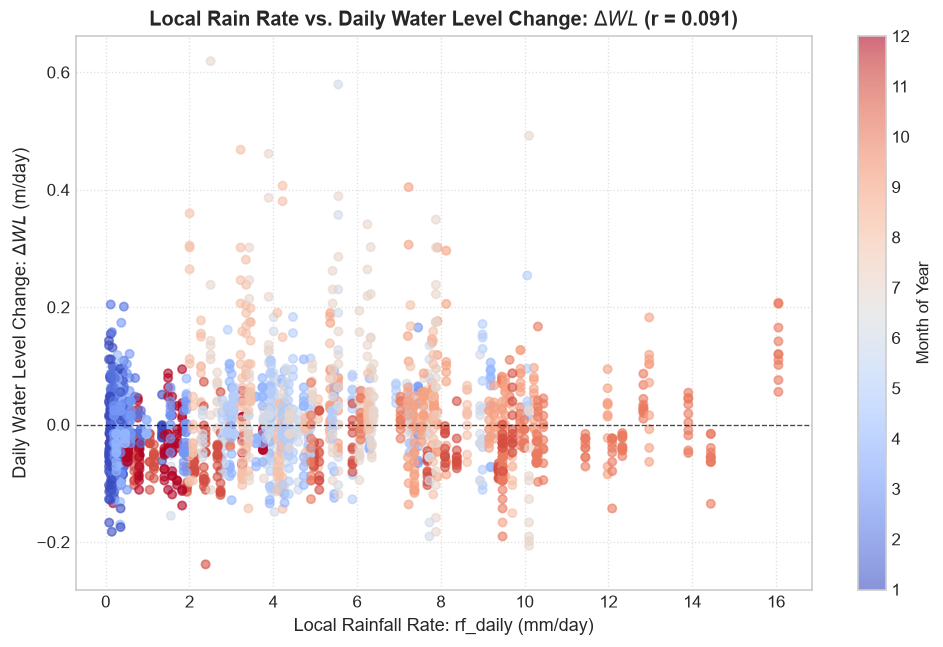

In [10]:
# Reindex rainfall to daily frequency and calculate daily rate
df_rain_daily = df_rain.set_index("date")[["rfh"]].reindex(df_unified["date"]).ffill().reset_index()
df_rain_daily["rf_daily"] = df_rain_daily["rfh"] / 10.0

df_scatter = pd.merge(df_unified, df_rain_daily, on="date")
df_scatter["WL_diff"] = df_scatter["WL"].diff()

clean_sc = df_scatter.dropna(subset=["rf_daily", "WL_diff"]).copy()
clean_sc["month"] = clean_sc["date"].dt.month

fig, ax = plt.subplots(figsize=(8.5, 5.5))
sc = ax.scatter(clean_sc["rf_daily"], clean_sc["WL_diff"],
                c=clean_sc["month"], cmap="coolwarm", alpha=0.6, s=25)
cbar = plt.colorbar(sc, ax=ax, ticks=range(1, 13))
cbar.set_label("Month of Year", fontsize=10)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
r_rf_diff = clean_sc["rf_daily"].corr(clean_sc["WL_diff"])

ax.set_title(f"Local Rain Rate vs. Daily Water Level Change: $\\Delta WL$ (r = {r_rf_diff:.3f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Local Rainfall Rate: rf_daily (mm/day)", fontsize=11)
ax.set_ylabel("Daily Water Level Change: $\\Delta WL$ (m/day)", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()



This scatter plot checks whether local rainfall directly causes the Bassac water level to rise or fall from one day to the next.

Each dot is one day.  
- Horizontal position = how much it rained that day  
- Vertical position = how much the river level changed that day  

The dots are scattered all over with almost no clear pattern, and the correlation is very weak

**Meaning:** Local rain by itself does not strongly control daily changes in the Bassac water level. The big rises and falls are driven mainly by the upstream Mekong flow, not by rain falling nearby.

## 6. Correlation Analysis & Feature Interactions

Here we construct the 11 candidate inputs and the 1-day-ahead target ($WL_{\text{next}}$) specified in the modeling plan:
- **Target ($y$):** `WL_next`
- **Autoregressive ($X$):** `WL`, `WL_lag1`, `WL_lag2`, `WL_lag3`, `WL_diff`
- **Discharge ($X$):** `upstream_discharge_lag1`, `upstream_discharge_diff`
- **Rainfall ($X$):** `rf_daily`, `r1h`, `r3h`, `rfq` (lagged by 1 full dekad before forward-filling to prevent leakage)

### Plot 8: Full Correlation Heatmap
Evaluates linear dependencies between each predictor and tomorrow's water level target.

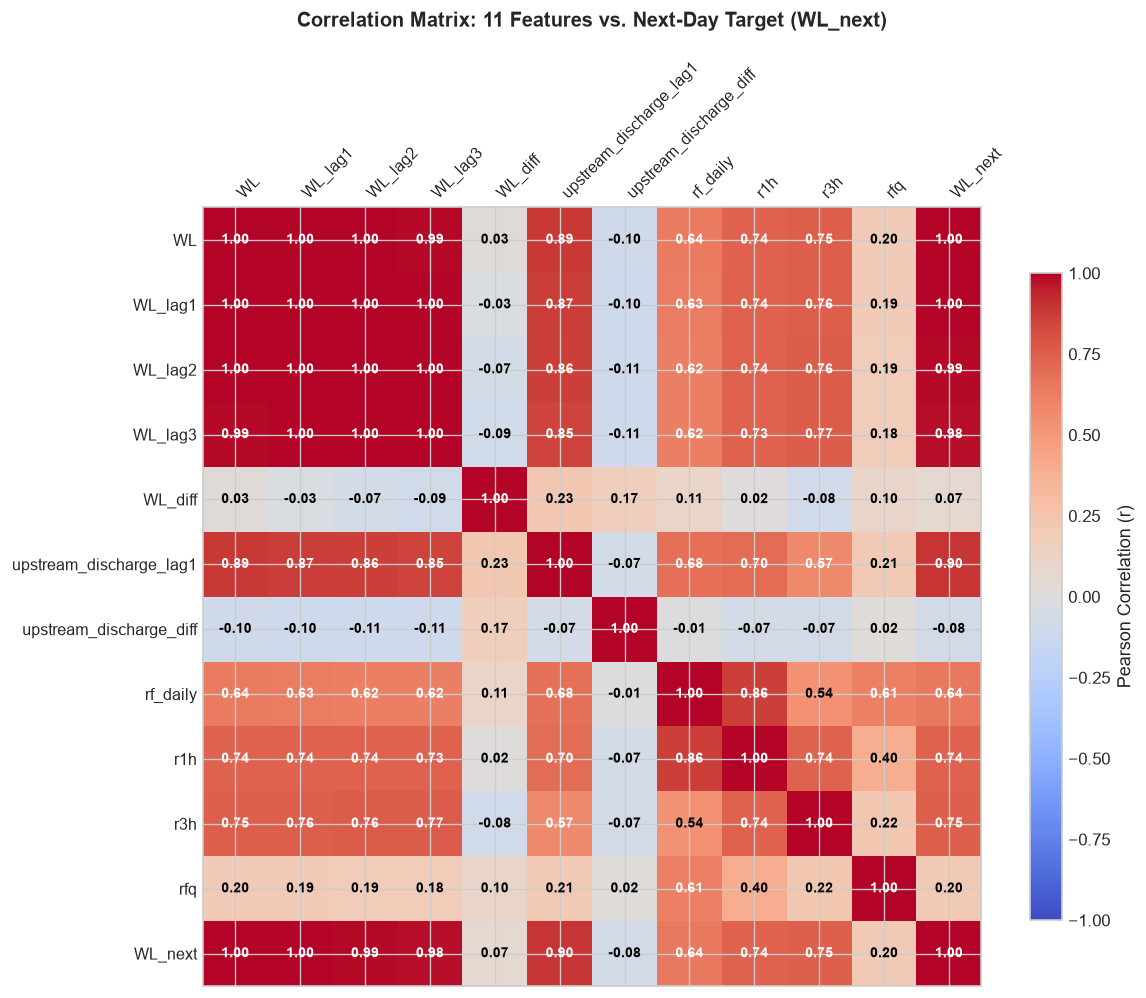

In [11]:
# 1. Feature assembly
df_mat = df_unified[["date", "WL"]].copy()
df_mat["WL_next"] = df_mat["WL"].shift(-1)
df_mat["WL_lag1"] = df_mat["WL"].shift(1)
df_mat["WL_lag2"] = df_mat["WL"].shift(2)
df_mat["WL_lag3"] = df_mat["WL"].shift(3)
df_mat["WL_diff"] = df_mat["WL"] - df_mat["WL_lag1"]

# 2. Upstream discharge
df_q_map = df_glofas.set_index("date")["upstream_discharge"].reindex(df_mat["date"])
df_mat["upstream_discharge"] = df_q_map.values
df_mat["upstream_discharge_lag1"] = df_mat["upstream_discharge"].shift(1)
df_mat["upstream_discharge_diff"] = df_mat["upstream_discharge"] - df_mat["upstream_discharge_lag1"]

# 3. Lag rainfall by 1 full dekad before ffill (prevent temporal leakage)
df_r_leak_free = df_rain.sort_values("date").copy()
for c in ["rfh", "r1h", "r3h", "rfq"]:
    df_r_leak_free[c] = df_r_leak_free[c].shift(1)

df_r_mapped = df_r_leak_free.set_index("date")[["rfh", "r1h", "r3h", "rfq"]].reindex(df_mat["date"]).ffill().reset_index()
df_mat["rf_daily"] = df_r_mapped["rfh"] / 10.0
df_mat["r1h"] = df_r_mapped["r1h"]
df_mat["r3h"] = df_r_mapped["r3h"]
df_mat["rfq"] = df_r_mapped["rfq"]

feature_order = [
    "WL", "WL_lag1", "WL_lag2", "WL_lag3", "WL_diff",
    "upstream_discharge_lag1", "upstream_discharge_diff",
    "rf_daily", "r1h", "r3h", "rfq", "WL_next"
]

corr = df_mat[feature_order].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8.5))
cax = ax.matshow(corr, cmap="coolwarm", vmin=-1.0, vmax=1.0)
fig.colorbar(cax, ax=ax, shrink=0.8, label="Pearson Correlation (r)")

ax.set_xticks(range(len(feature_order)))
ax.set_yticks(range(len(feature_order)))
ax.set_xticklabels(feature_order, rotation=45, ha="left", fontsize=9.5)
ax.set_yticklabels(feature_order, fontsize=9.5)

for i in range(len(feature_order)):
    for j in range(len(feature_order)):
        val = corr.iloc[i, j]
        text_color = "white" if abs(val) > 0.55 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=8.5, fontweight="bold")

ax.set_title("Correlation Matrix: 11 Features vs. Next-Day Target (WL_next)", fontsize=12, fontweight="bold", pad=20)
plt.tight_layout()
plt.show()



This heatmap shows how strongly each factor is related to **tomorrow’s water level** on the Bassac River.

**Strongest predictors (dark red):**
- Today’s water level and the last few days’ water levels → almost perfect correlation (0.98–1.00). The river level does not jump suddenly, so knowing today’s level already tells you a lot about tomorrow’s.
- Upstream Mekong discharge from the previous day → very strong correlation (0.90).

**Moderate predictors:**
- Local rainfall (daily and short-term totals) → medium correlation (around 0.64–0.75). Rain helps a bit but is not the main driver.

**Weak predictors (pale colors):**
- Day-to-day changes in water level or discharge → almost no useful relationship with tomorrow’s level.

**Bottom line:**  
The best simple predictors of tomorrow’s Bassac water level are:  
1. Today’s water level, and  
2. Yesterday’s Mekong discharge at Phnom Penh.

### Plot 9: Persistence Benchmark & Hydrodynamic Phase Space
- **Left:** Today's $WL$ vs. Tomorrow's $WL_{\text{next}}$. The points cluster tightly along the $1:1$ diagonal, proving that persistence is a formidable baseline.
- **Right:** Upstream discharge ($Q_{\text{lag1}}$) vs. daily rate of change ($\Delta \text{WL}$), showing how upstream flow drives the direction of water level shifts.

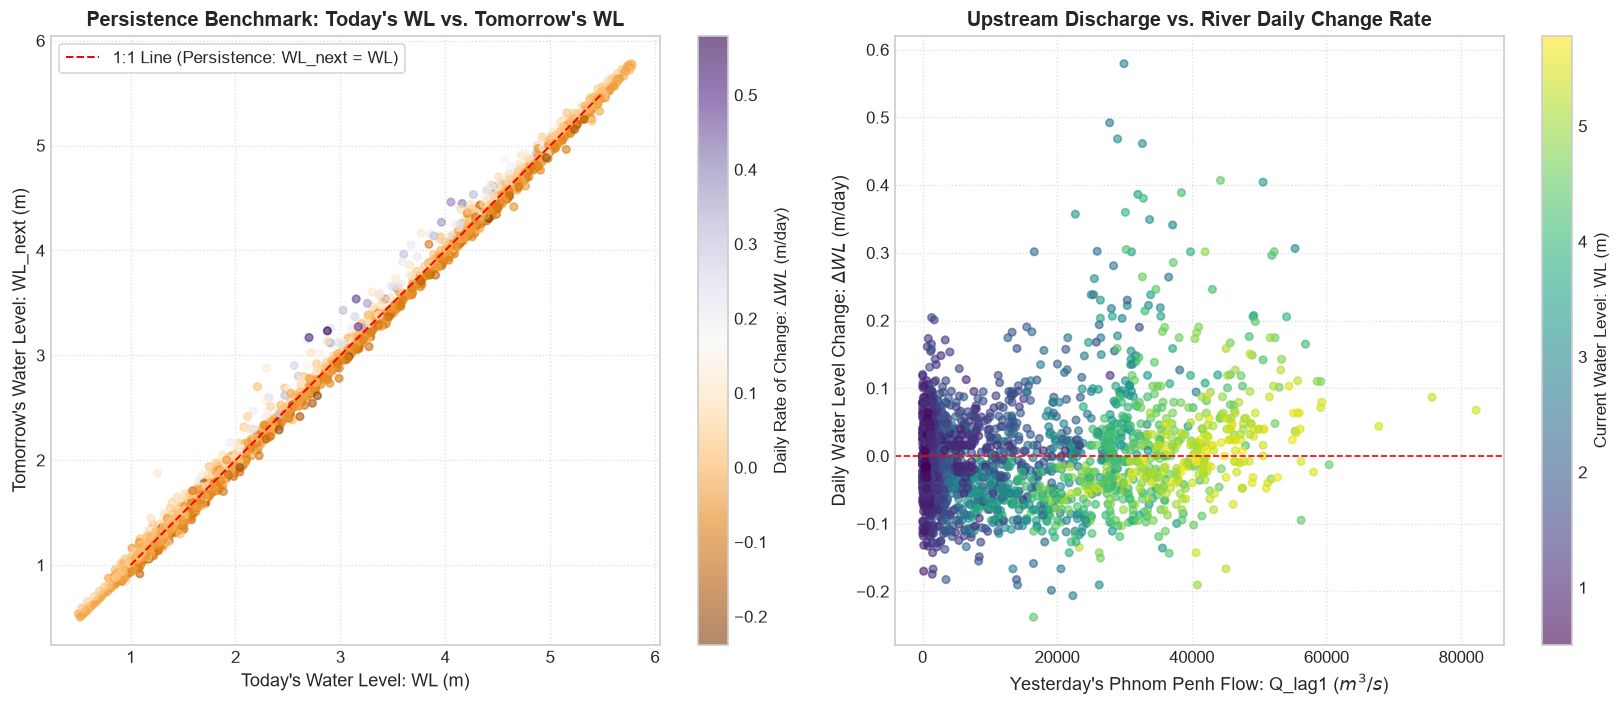

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
sub_phase = df_mat.dropna(subset=["WL", "WL_next", "upstream_discharge_lag1", "WL_diff"]).copy()

# 1. Persistence Scatter (Today vs. Tomorrow)
sc1 = ax1.scatter(sub_phase["WL"], sub_phase["WL_next"],
                  c=sub_phase["WL_diff"], cmap="PuOr", alpha=0.6, s=20)
ax1.plot([1.0, 5.5], [1.0, 5.5], color="red", linestyle="--", linewidth=1.2, label="1:1 Line (Persistence: WL_next = WL)")
cbar1 = plt.colorbar(sc1, ax=ax1)
cbar1.set_label("Daily Rate of Change: $\\Delta WL$ (m/day)", fontsize=10)

ax1.set_title("Persistence Benchmark: Today's WL vs. Tomorrow's WL", fontsize=12, fontweight="bold")
ax1.set_xlabel("Today's Water Level: WL (m)", fontsize=11)
ax1.set_ylabel("Tomorrow's Water Level: WL_next (m)", fontsize=11)
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. Upstream Discharge vs. Daily Rise/Fall
sc2 = ax2.scatter(sub_phase["upstream_discharge_lag1"], sub_phase["WL_diff"],
                  c=sub_phase["WL"], cmap="viridis", alpha=0.6, s=20)
ax2.axhline(0, color="red", linestyle="--", linewidth=1.0)
cbar2 = plt.colorbar(sc2, ax=ax2)
cbar2.set_label("Current Water Level: WL (m)", fontsize=10)

ax2.set_title("Upstream Discharge vs. River Daily Change Rate", fontsize=12, fontweight="bold")
ax2.set_xlabel("Yesterday's Phnom Penh Flow: Q_lag1 ($m^3/s$)", fontsize=11)
ax2.set_ylabel("Daily Water Level Change: $\\Delta WL$ (m/day)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()



**Left chart:**  
This checks a basic idea called “persistence”: if I just say “tomorrow’s water level will be the same as today’s,” how good is that guess?  
Almost all the points sit right on the red diagonal line, meaning tomorrow’s level is usually extremely close to today’s. The river changes slowly, so knowing today’s level already gives a very strong prediction of tomorrow’s level.

**Right chart:**  
This looks at whether yesterday’s Mekong flow (at Phnom Penh) can tell us how much the Bassac will rise or fall today.  
When upstream flow is low, the daily change is usually small (points clustered near zero). When upstream flow is high, the water level can rise more noticeably, but the relationship is still quite scattered. Color shows the current water level — higher levels (yellow-green) tend to appear when upstream flow is also high.

## 7. Conclusions & Implications for Machine Learning

1. **High Autoregressive Correlation ($r = 0.999$):**
   * The strong day-to-day persistence explains why the simple benchmark $\hat{y}_{t+1} = y_t$ achieves low baseline error (~3–5 cm).
   * To be practically useful, predictive models (Ridge, Random Forest, XGBoost) must outperform persistence at critical inflection periods (onset of the monsoon rising limb and the peak flood crest).

2. **Upstream Mekong Discharge as an Early-Warning Signal ($r = 0.85$):**
   * Cross-correlation confirms a 1-to-2 day lead time between discharge passing Phnom Penh and peak water level changes at Koh Khel.
   * This gives the machine learning models physical predictive power that autoregressive history alone cannot capture.

3. **Local Rainfall as a Catchment Saturation Driver:**
   * Local dekadal rainfall correlates with intermediate soil saturation (`r1h`, `r3h`).
   * Lagging rainfall by 1 dekad completely eliminates future data leakage while preserving seasonal moisture context.

4. **Station Calibration Consistency:**
   * Calibrating Koh Khel ($WL_{\text{cal}} = 0.7936 \cdot WL_{\text{raw}} - 0.4725$) seamlessly extends the timeline into 2024–2026 without artificial datum discontinuities.